# Static reference for the cell deformation

How round are the cells **without flow**? This notebook gives the reference for the deformation measured in the
Phantom recordings (`cell_trajectory_morphology_thesis_v4`). It does not change any existing results.

**Part A (fast, no Cellpose):** reads the `summary.csv` files that `cellpose_original_crops` wrote for the
z-stack folders. They contain the eccentricity $e$ and the circularity of every mask. From these:

* axis ratio $L/B = 1/\sqrt{1-e^2}$ (axes of the ellipse with the same second moments as the mask, as in the tracking notebook)
* $D_\mathrm{ellipse} = (L-B)/(L+B)$
* RT-DC deformation $1-c$ with $c=\sqrt{4\pi A/P^2}$
* equivalent diameter from the area and the pixel size of the day (2×2 binning on 180326, 250326, 110526)

Two sets are reported: the masks accepted by the strict filter (these are the training images) and all masks that
pass the permissive filter of the high-speed recordings, so that both use the same thresholds.

**Part B (same pipeline as the flow data, needs Cellpose):** takes a random sample of z-stack crops, resamples them to
0.925 µm/px, segments them with the high-speed Cellpose model and the same parameters and filter as the Phantom
recordings, and measures $D_\mathrm{ellipse}$, $1-c$ and the orientation of the major axis. This removes the difference
in pixel size and segmentation between the static and the flowing cells.

**Limitation:** the z-stack was recorded with the Zyla on a different microscope. The orientation in Part B
therefore refers to the Zyla image axes. It shows whether static cells have a preferred orientation in the image,
but it is not a test for an anisotropy of the Phantom optics.


In [1]:
from pathlib import Path
import re, inspect, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tifffile
from scipy import ndimage as ndi
from skimage.measure import label, regionprops, perimeter_crofton
from skimage.segmentation import find_boundaries
from skimage.morphology import convex_hull_image
from skimage.transform import rescale

pd.set_option('display.width', 200)
print('Imports OK')

Imports OK


## 1. Settings

In [6]:
# Folder with the z-stack crops and their summary.csv files (searched recursively)
ZSTACK_CROP_ROOT = Path('/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack')
# v4 outputs for the comparison with the flow data
V4_DETECTION_SUMMARY = Path('/Volumes/Extreme SSD/Masterarbeit/Code/PC/cell_thesis_results_v4_2/run_20261012_125134_843989/tables/detection_summary.csv')
OUTPUT_DIR = Path('static_deformation_results')

PIXEL_SIZE_UNBINNED_UM = 0.325
BINNED_DATES = {'180326', '250326', '110526'}      # 2x2 binning (00_check_binning)
TARGET_PIXEL_SIZE_UM = 0.925                         # Phantom pixel size

# Permissive filter of the high-speed recordings (Methods, Table shape_filter), area in um^2
PERMISSIVE = dict(min_area_um2=100 * TARGET_PIXEL_SIZE_UM**2, min_circularity=0.20, max_aspect_ratio=4.0,
                  min_solidity=0.75, max_eccentricity=0.99, max_radial_std_norm=0.50, min_convexity_ratio=0.75)
D_EQ_RANGE_UM = (8.0, 30.0)                          # removes debris and clusters

# Part B
RUN_PART_B = False
HIGH_SPEED_MODEL = r'/Volumes/Extreme SSD/Masterarbeit/cellpose/highspeed/models/NIH3T3/models/high_speed_1'
N_PER_DAY = 300
RANDOM_SEED = 0
PAD_UM = 10.0
CP = dict(diameter=20, flow_threshold=0.4, cellprob_threshold=-1.5, min_size=50)
EDGE_MARGIN_PX = 3
PATH_REPLACEMENTS = [
    # (old prefix in summary.csv, new prefix), if the crops were moved
]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / 'figures').mkdir(exist_ok=True)

## 2. Part A: read the summary.csv files

In [7]:
def date_of(path):
    m = [p for p in Path(path).parts if re.fullmatch(r'\d{6}', p)]
    return m[-1] if m else None

def line_of(path):
    s = str(path)
    return 'NIH3T3' if 'NIH3T3' in s else ('HeLa' if 'HeLa' in s else None)

files = sorted(p for p in ZSTACK_CROP_ROOT.rglob('summary.csv') if not p.name.startswith('._'))
parts = []
for f in files:
    t = pd.read_csv(f)
    t['summary_file'] = str(f)
    t['date'] = date_of(f)
    t['cell_type'] = line_of(f)
    parts.append(t)
    print(f'{f}: {len(t):,} masks')
raw = pd.concat(parts, ignore_index=True)
raw = raw.loc[raw.cell_type.notna() & raw.date.notna()].copy()
raw['pixel_size_um'] = np.where(raw.date.isin(BINNED_DATES), 2 * PIXEL_SIZE_UNBINNED_UM, PIXEL_SIZE_UNBINNED_UM)

m = raw.dropna(subset=['eccentricity', 'area', 'circularity']).copy()
r = np.sqrt(np.clip(1 - m.eccentricity**2, 0, 1))
m['axis_ratio'] = 1 / r
m['deformation'] = (1 - r) / (1 + r)
m['deformation_rtdc'] = 1 - np.sqrt(m.circularity.clip(lower=0))
m['area_um2'] = m.area * m.pixel_size_um**2
m['equivalent_diameter_um'] = 2 * np.sqrt(m.area_um2 / np.pi)

perm = ((m.area_um2 >= PERMISSIVE['min_area_um2']) & (m.circularity >= PERMISSIVE['min_circularity'])
        & (m.aspect_ratio <= PERMISSIVE['max_aspect_ratio']) & (m.solidity >= PERMISSIVE['min_solidity'])
        & (m.eccentricity <= PERMISSIVE['max_eccentricity'])
        & (m.radial_std_norm <= PERMISSIVE['max_radial_std_norm'])
        & (m.convexity_ratio >= PERMISSIVE['min_convexity_ratio'])
        & m.equivalent_diameter_um.between(*D_EQ_RANGE_UM))
m['set_strict_accepted'] = m.status.eq('accepted')
m['set_permissive'] = perm
print(f'{len(m):,} masks with metrics, {m.set_strict_accepted.sum():,} strict-accepted, {m.set_permissive.sum():,} permissive')

/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack/HeLa_new/130426/summary.csv: 5,316 masks
/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack/HeLa_new/180326/summary.csv: 411 masks
/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack/HeLa_new/220726/summary.csv: 14,498 masks
/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack/HeLa_new/250326/summary.csv: 9,285 masks
/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack/NIH3T3_new/110526/summary.csv: 10,617 masks
/Volumes/Extreme SSD/Masterarbeit/cellpose/z-stack/NIH3T3_new/130526/summary.csv: 4,803 masks
44,930 masks with metrics, 40,229 strict-accepted, 40,433 permissive


## 3. Part A: summary per cell line and day

In [8]:
def summarize(df, groups):
    q = lambda p: (lambda s: s.quantile(p))
    return df.groupby(groups).agg(
        n=('deformation', 'size'), D_median=('deformation', 'median'),
        D_q25=('deformation', q(.25)), D_q75=('deformation', q(.75)),
        AR_median=('axis_ratio', 'median'), one_minus_c_median=('deformation_rtdc', 'median'),
        d_eq_median_um=('equivalent_diameter_um', 'median')).reset_index()

rows = []
for name, col in [('strict accepted (training images)', 'set_strict_accepted'), ('permissive filter', 'set_permissive')]:
    rows.append(summarize(m.loc[m[col]], ['cell_type', 'date', 'pixel_size_um']).assign(set=name))
    rows.append(summarize(m.loc[m[col]], ['cell_type']).assign(set=name, date='all', pixel_size_um=np.nan))
static_A = pd.concat(rows, ignore_index=True)
static_A.to_csv(OUTPUT_DIR / 'static_deformation_partA.csv', index=False)
display(static_A.round(4))

,cell_type,date,pixel_size_um,n,D_median,D_q25,D_q75,AR_median,one_minus_c_median,d_eq_median_um,set
0,HeLa,130426,0.325,4935,0.0470,0.0258,0.0832,1.0987,0.0087,20.9867,strict accepted (training images)
1,HeLa,180326,0.650,368,0.0317,0.0176,0.0637,1.0654,0.0068,23.7097,strict accepted (training images)
2,HeLa,220726,0.325,13476,0.0663,0.0382,0.1102,1.1419,0.0131,20.0192,strict accepted (training images)
3,HeLa,250326,0.650,8629,0.0336,0.0186,0.0613,1.0696,0.0142,22.7723,strict accepted (training images)
4,NIH3T3,110526,0.650,8672,0.0600,0.0347,0.0970,1.1276,0.0151,23.9917,strict accepted (training images)
5,NIH3T3,130526,0.325,4149,0.0271,0.0171,0.0439,1.0558,0.0061,22.7132,strict accepted (training images)
6,HeLa,all,NaN,27408,0.0508,0.0267,0.0909,1.1070,0.0123,21.0379,strict accepted (training images)
7,NIH3T3,all,NaN,12821,0.0462,0.0251,0.0827,1.0968,0.0108,23.3755,strict accepted (training images)
8,HeLa,130426,0.325,5143,0.0499,0.0269,0.0930,1.1051,0.0092,20.7450,permissive filter
9,HeLa,180326,0.650,286,0.0403,0.0223,0.0870,1.0839,0.0102,21.2952,permissive filter


## 4. Comparison with the flow data
From the v4 file `detection_summary.csv`: medians and quartiles of all detections (`all_detections`) and of the
track medians (`track_medians_primary`).

metric,cell_type,imaging_mode,flow_rate_ul_min,scenario,axis_ratio,deformation,deformation_rtdc,equivalent_diameter_um
0,HeLa,BF,30,all_detections,1.090,0.043,0.005,14.387
1,HeLa,BF,30,track_medians_primary,1.075,0.036,0.002,15.375
2,HeLa,BF,150,all_detections,1.130,0.061,0.009,18.048
3,HeLa,BF,150,track_medians_primary,1.143,0.067,0.010,18.627
4,HeLa,BF,300,all_detections,1.077,0.037,0.006,14.798
5,HeLa,BF,300,track_medians_primary,1.079,0.038,0.004,14.650
6,HeLa,Ph2,30,all_detections,1.094,0.045,0.006,16.034
7,HeLa,Ph2,30,track_medians_primary,1.094,0.045,0.006,16.060
8,HeLa,Ph2,150,all_detections,1.083,0.040,0.007,15.726
9,HeLa,Ph2,150,track_medians_primary,1.106,0.050,0.015,15.358


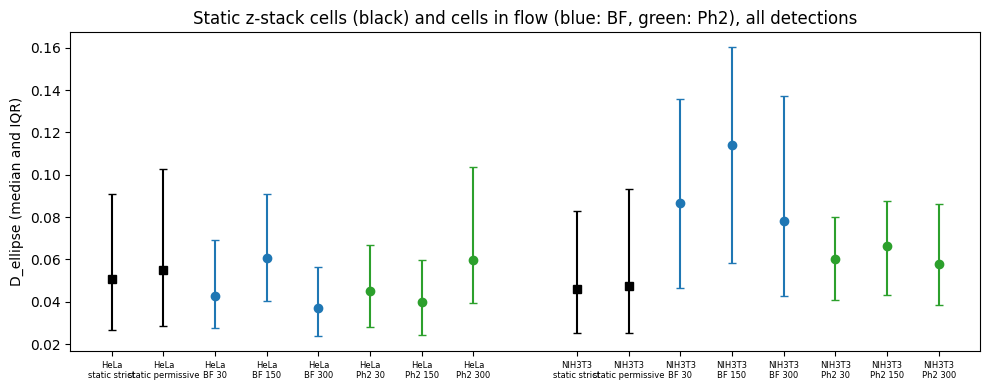

In [9]:
flow = pd.read_csv(V4_DETECTION_SUMMARY)
flow = flow.loc[flow.metric.isin(['deformation', 'deformation_rtdc', 'axis_ratio', 'equivalent_diameter_um'])
                & flow.scenario.isin(['all_detections', 'track_medians_primary'])]
flow_tab = flow.pivot_table(index=['cell_type', 'imaging_mode', 'flow_rate_ul_min', 'scenario'],
                            columns='metric', values='median').reset_index()
display(flow_tab.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
xt, xl, x = [], [], 0
for ct in ['HeLa', 'NIH3T3']:
    for name, col in [('static strict', 'set_strict_accepted'), ('static permissive', 'set_permissive')]:
        s = m.loc[m[col] & m.cell_type.eq(ct), 'deformation']
        if len(s):
            ax.errorbar(x, s.median(), yerr=[[s.median() - s.quantile(.25)], [s.quantile(.75) - s.median()]],
                        fmt='s', color='k', capsize=3)
            xt.append(x); xl.append(f'{ct}\n{name}'); x += 1
    f = flow.loc[(flow.cell_type == ct) & (flow.metric == 'deformation') & (flow.scenario == 'all_detections')]
    for row in f.sort_values(['imaging_mode', 'flow_rate_ul_min']).itertuples():
        ax.errorbar(x, row.median, yerr=[[row.median - row.q25], [row.q75 - row.median]], fmt='o',
                    color='tab:blue' if row.imaging_mode == 'BF' else 'tab:green', capsize=3)
        xt.append(x); xl.append(f'{ct}\n{row.imaging_mode} {row.flow_rate_ul_min:g}'); x += 1
    x += 1
ax.set_xticks(xt); ax.set_xticklabels(xl, fontsize=6)
ax.set_ylabel('D_ellipse (median and IQR)')
ax.set_title('Static z-stack cells (black) and cells in flow (blue: BF, green: Ph2), all detections')
fig.tight_layout(); fig.savefig(OUTPUT_DIR / 'figures' / 'static_vs_flow_partA.pdf'); plt.show()

## 5. Part B: same segmentation and pixel size as the flow data (optional)
Set `RUN_PART_B = True`. The crops are padded, resampled to 0.925 µm/px, segmented with the high-speed model
and measured with the same functions and filter as `cellpose_tiff_flow_tracking_optimized`.

In [10]:
# Shape metrics copied from cellpose_tiff_flow_tracking_optimized (same definitions)
def compute_radial_std_norm(mask, cr, cc):
    ys, xs = np.where(find_boundaries(mask, mode='inner'))
    if len(ys) < 5:
        return 0.0
    d = np.sqrt((ys - cr)**2 + (xs - cc)**2)
    return float(d.std() / d.mean()) if d.mean() > 1e-6 else 0.0

def compute_convexity_ratio(mask, perim):
    if perim <= 0:
        return 1.0
    try:
        cp = float(perimeter_crofton(convex_hull_image(mask), directions=4))
        return cp / perim if cp > 0 else 1.0
    except Exception:
        return 1.0

def shape_metrics(mask):
    mk = ndi.binary_fill_holes(ndi.binary_closing(mask.astype(bool), iterations=1))
    props = regionprops(label(mk.astype(np.uint8)))
    if not props:
        return None
    reg = max(props, key=lambda p: p.area)
    area = float(reg.area)
    try:
        perim = float(perimeter_crofton(mk, directions=4))
    except Exception:
        perim = float(reg.perimeter)
    minr, minc, maxr, maxc = reg.bbox
    h, w = maxr - minr, maxc - minc
    major, minor = float(reg.axis_major_length), float(reg.axis_minor_length)
    cr, cc = reg.centroid
    return dict(area=area, perimeter=perim, circularity=4 * np.pi * area / perim**2 if perim > 0 else 0.0,
                aspect_ratio=max(h, w) / min(h, w) if min(h, w) > 0 else np.inf,
                solidity=float(reg.solidity), eccentricity=float(reg.eccentricity),
                radial_std_norm=compute_radial_std_norm(mk, cr, cc), convexity_ratio=compute_convexity_ratio(mk, perim),
                major_axis_px=major, minor_axis_px=minor, orientation_rad=float(reg.orientation),
                deformation=(major - minor) / (major + minor) if major + minor > 0 else np.nan,
                bbox_y0=minr, bbox_x0=minc, bbox_y1=maxr, bbox_x1=maxc)

def passes_permissive(mt):
    return (mt['area'] >= 100 and mt['circularity'] >= PERMISSIVE['min_circularity']
            and mt['aspect_ratio'] <= PERMISSIVE['max_aspect_ratio'] and mt['solidity'] >= PERMISSIVE['min_solidity']
            and mt['eccentricity'] <= PERMISSIVE['max_eccentricity']
            and mt['radial_std_norm'] <= PERMISSIVE['max_radial_std_norm']
            and mt['convexity_ratio'] >= PERMISSIVE['min_convexity_ratio'])

def fix_path(p):
    p = str(p)
    for old, new in PATH_REPLACEMENTS:
        if p.startswith(old):
            p = new + p[len(old):]
    return Path(p)

def normalize_percentile(img, lo=1, hi=99):
    a = img.astype(np.float32); l, h = np.percentile(a, [lo, hi])
    return np.clip((a - l) / (h - l), 0, 1) if h > l else np.zeros_like(a)

def prepare(crop, px_src):
    pad = int(round(PAD_UM / px_src))
    border = np.concatenate([crop[0], crop[-1], crop[:, 0], crop[:, -1]])
    padded = np.pad(crop.astype(np.float32), pad, mode='constant', constant_values=float(np.median(border)))
    return rescale(padded, px_src / TARGET_PIXEL_SIZE_UM, anti_aliasing=True, preserve_range=True)

In [11]:
def load_cellpose():
    from cellpose import models, core
    import torch
    try:
        gpu = bool(core.use_gpu())
    except Exception:
        gpu = False
    if not gpu and hasattr(torch.backends, 'mps'):
        gpu = torch.backends.mps.is_available()
    return models.CellposeModel(gpu=gpu, pretrained_model=str(HIGH_SPEED_MODEL))

def segment(model, img):
    kw = dict(diameter=CP['diameter'], flow_threshold=CP['flow_threshold'],
              cellprob_threshold=CP['cellprob_threshold'], min_size=CP['min_size'], normalize=True)
    params = set(inspect.signature(model.eval).parameters)
    if 'channels' in params:
        kw['channels'] = [0, 0]
    elif 'channel_axis' in params:
        kw['channel_axis'] = None
    out = model.eval(normalize_percentile(img), **kw)
    return np.asarray(out[0] if isinstance(out, (list, tuple)) else out)

if RUN_PART_B:
    model = load_cellpose()
    acc = m.loc[m.set_strict_accepted & m.output_path.notna()]
    idx = []
    for _, g in acc.groupby(['cell_type', 'date']):
        idx += list(g.sample(min(len(g), N_PER_DAY), random_state=RANDOM_SEED).index)
    sample = acc.loc[idx]
    rowsB = []
    for i, row in enumerate(sample.itertuples()):
        rec = dict(cell_type=row.cell_type, date=row.date, source_pixel_size_um=row.pixel_size_um,
                   crop=str(row.output_path), status='error', reason='')
        try:
            img = prepare(np.squeeze(tifffile.imread(fix_path(row.output_path))), row.pixel_size_um)
            masks = segment(model, img)
            if masks.max() == 0:
                rec['reason'] = 'no mask'
            else:
                cy, cx = np.array(masks.shape) // 2
                lid = masks[cy, cx] or np.bincount(masks.ravel())[1:].argmax() + 1
                mt = shape_metrics(masks == lid)
                H, W = masks.shape
                edge = (mt['bbox_y0'] <= EDGE_MARGIN_PX or mt['bbox_x0'] <= EDGE_MARGIN_PX
                        or mt['bbox_y1'] >= H - EDGE_MARGIN_PX or mt['bbox_x1'] >= W - EDGE_MARGIN_PX)
                ok = passes_permissive(mt) and not edge
                rec.update(mt, status='accepted' if ok else 'rejected', reason='' if ok else ('edge' if edge else 'filter'))
        except Exception as err:
            rec['reason'] = f'{type(err).__name__}: {err}'
        rowsB.append(rec)
        if (i + 1) % 100 == 0:
            print(f'{i + 1}/{len(sample)}', flush=True); gc.collect()
    B = pd.DataFrame(rowsB)
    ok = B.status.eq('accepted')
    B['deformation_rtdc'] = 1 - np.sqrt(B.circularity.clip(lower=0))
    B['axis_ratio'] = B.major_axis_px / B.minor_axis_px
    B['equivalent_diameter_um'] = 2 * np.sqrt(B.area / np.pi) * TARGET_PIXEL_SIZE_UM
    # Same angle convention as v4 (flow direction 180 deg = image x axis); here relative to the Zyla x axis
    major_vs_x = 90.0 - np.rad2deg(B.orientation_rad.astype(float))
    off = major_vs_x % 180.0
    B['inclination_to_x_deg'] = np.minimum(off, 180.0 - off)
    B.to_csv(OUTPUT_DIR / 'static_deformation_partB_crops.csv', index=False)
    print(B.status.value_counts())
    static_B = B.loc[ok].groupby('cell_type').agg(
        n=('deformation', 'size'), D_median=('deformation', 'median'),
        D_q25=('deformation', lambda s: s.quantile(.25)), D_q75=('deformation', lambda s: s.quantile(.75)),
        AR_median=('axis_ratio', 'median'), one_minus_c_median=('deformation_rtdc', 'median'),
        d_eq_median_um=('equivalent_diameter_um', 'median'),
        inclination_median_deg=('inclination_to_x_deg', 'median'),
        frac_major_axis_within_45deg_of_x=('inclination_to_x_deg', lambda s: (s < 45).mean())).reset_index()
    static_B.to_csv(OUTPUT_DIR / 'static_deformation_partB.csv', index=False)
    display(static_B.round(4))
else:
    print('Part B skipped (RUN_PART_B = False).')

Part B skipped (RUN_PART_B = False).


## 6. What to report
* Results, Section *Cell size and deformation*, bullet *Static reference*: median $D_\mathrm{ellipse}$ and IQR of the
  static cells per cell line (Part B if available, otherwise Part A permissive), next to the flow values.
* If the static cells have about the same $D_\mathrm{ellipse}$ as the cells in flow, the measured deformation in flow is
  mainly the shape the cells already have, plus segmentation noise.
* Part B, orientation: a median near 45° and a fraction near 0.5 mean no preferred orientation of static cells.